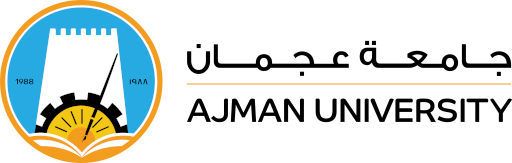

<p>
College: Engineering and Information Technology<br>
Department: Information Technology<br>
Program: Data Analytics<br>
Academic Semester: Spring 2025-2026<br>
Course: DAT405 Machine Learning Lab<br>
Course Instructor: Dr. Mahmoud AlShboul<br>
</p></center>

# **Lab 2: Dimensionality Reduction**

## Principal Component Analysis (PCA)
1. PCA is an unsupervised pre-processing task that is carried out before applying any ML algorithm. PCA is based on “orthogonal linear transformation” which is a mathematical technique to project the attributes of a data set onto a new coordinate system. The attribute which describes the most variance is called the first principal component and is placed at the first coordinate.
2. Similarly, the attribute which stands second in describing variance is called a second principal component and so on. In short, the complete dataset can be expressed in terms of principal components. Usually, more than 90% of the variance is explained by two/three principal components.
3. Principal component analysis, or PCA, thus converts data from high dimensional space to low dimensional space by selecting the most important attributes that capture maximum information about the dataset.

Note: It is important to normalize the data before applying PCA, as it is a variance maximizing technique, it projects the original data onto directions which maximize the variance.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer

In [2]:
data=load_breast_cancer()

In [3]:
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [4]:
#printing the output classes
print(data['target_names'])

['malignant' 'benign']


In [5]:
#printing the input attributes
print(data['feature_names'])

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [6]:
#constructing a dataframe from the sklearn dataset
df1=pd.DataFrame(data['data'],columns=data['feature_names'])
print(f'The shape of the original dataframe: {df1.shape}')
# Scale data before applying PCA
scaler=StandardScaler()
scaler.fit(df1)
Scaled_data=scaler.transform(df1)

# Set PCA to three principal components
principal=PCA(n_components=3)
principal.fit(Scaled_data)
x=principal.transform(Scaled_data)

# Check the dimensions of data after PCA
print(f'The shape of the transformed dataframe: {x.shape}')

The shape of the original dataframe: (569, 30)
The shape of the transformed dataframe: (569, 3)


In [7]:
df1

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [8]:
#Printing the produced eigenvectors
principal.components_

array([[ 0.21890244,  0.10372458,  0.22753729,  0.22099499,  0.14258969,
         0.23928535,  0.25840048,  0.26085376,  0.13816696,  0.06436335,
         0.20597878,  0.01742803,  0.21132592,  0.20286964,  0.01453145,
         0.17039345,  0.15358979,  0.1834174 ,  0.04249842,  0.10256832,
         0.22799663,  0.10446933,  0.23663968,  0.22487053,  0.12795256,
         0.21009588,  0.22876753,  0.25088597,  0.12290456,  0.13178394],
       [-0.23385713, -0.05970609, -0.21518136, -0.23107671,  0.18611302,
         0.15189161,  0.06016536, -0.0347675 ,  0.19034877,  0.36657547,
        -0.10555215,  0.08997968, -0.08945723, -0.15229263,  0.20443045,
         0.2327159 ,  0.19720728,  0.13032156,  0.183848  ,  0.28009203,
        -0.21986638, -0.0454673 , -0.19987843, -0.21935186,  0.17230435,
         0.14359317,  0.09796411, -0.00825724,  0.14188335,  0.27533947],
       [-0.00853124,  0.0645499 , -0.00931422,  0.02869953, -0.1042919 ,
        -0.07409157,  0.00273384, -0.02556354, -0

Text(0, 0.5, 'pc2')

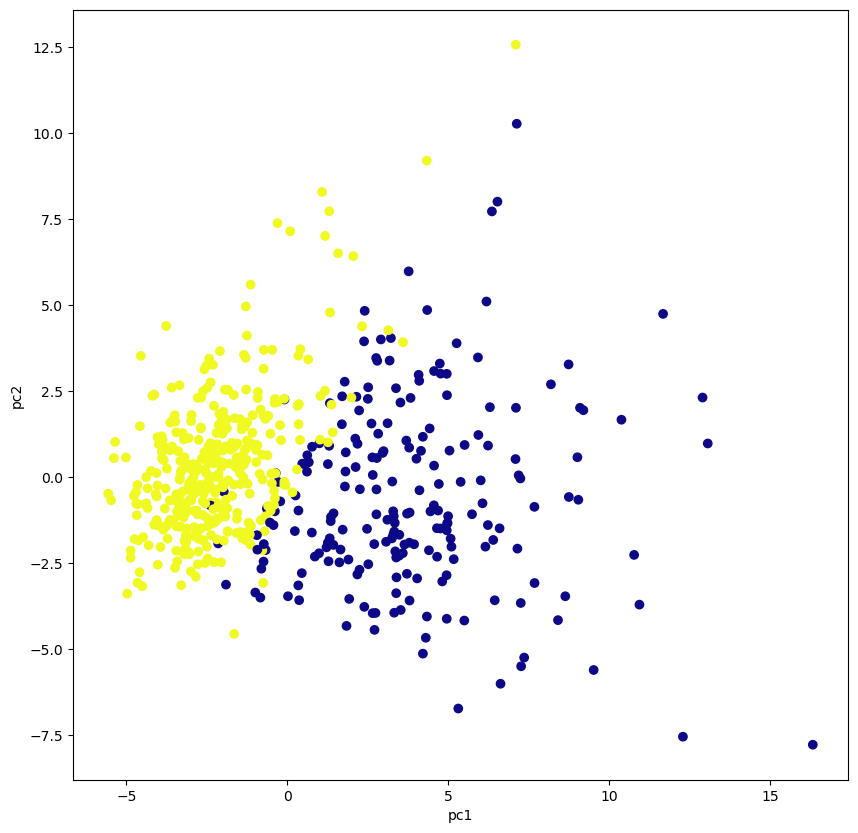

In [9]:
plt.figure(figsize=(10,10))
plt.scatter(x[:,0],x[:,1],c=data['target'],cmap='plasma')
plt.xlabel('pc1')
plt.ylabel('pc2')

Text(0.5, 0, 'PC3')

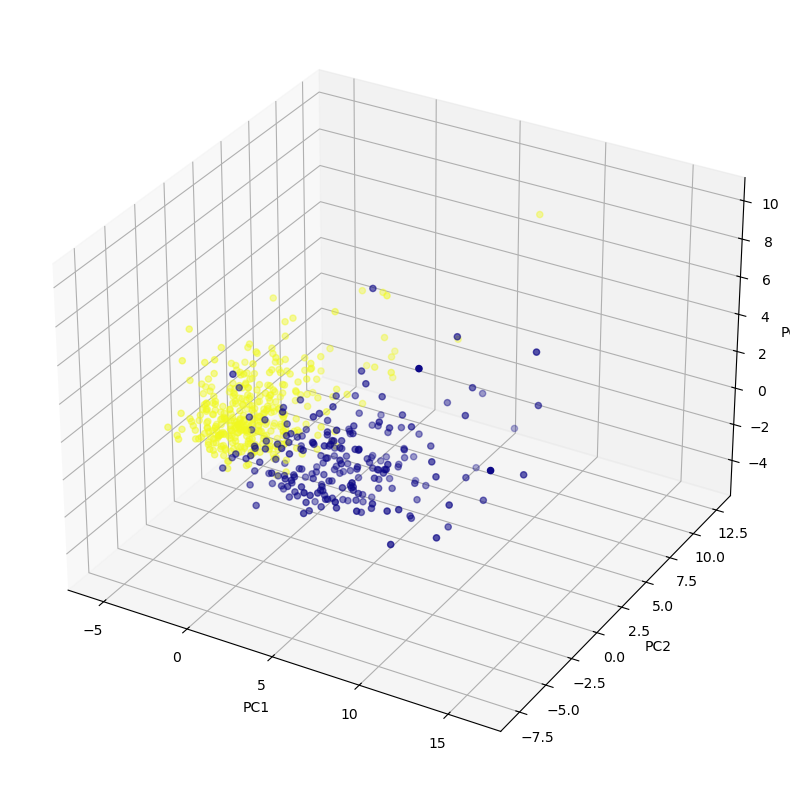

In [10]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10,10))
# 3D Projection
axis = fig.add_subplot(111, projection='3d')
# x[:,0]is pc1 ,x[:,1] is pc2,x[:,2] is pc3
axis.scatter(x[:,0],x[:,1],x[:,2], c=data['target'],cmap='plasma')
axis.set_xlabel("PC1", fontsize=10)
axis.set_ylabel("PC2", fontsize=10)
axis.set_zlabel("PC3", fontsize=10)

In [11]:
# The explained variance ratio is a measure of the proportion of the total variance in the original dataset that is explained by each principal component
print(principal.explained_variance_ratio_)

[0.44272026 0.18971182 0.09393163]


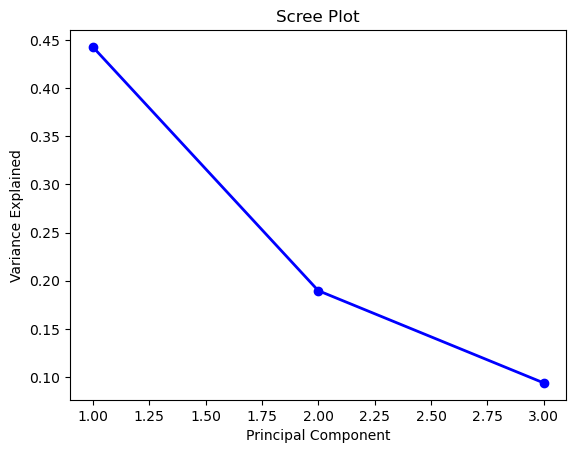

In [12]:
#creating a scree plot of the explained variance
import matplotlib.pyplot as plt
import numpy as np

PC_values = np.arange(principal.n_components_) + 1
plt.plot(PC_values, principal.explained_variance_ratio_, 'o-', linewidth=2, color='blue')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.show()

1. The first principal component explains 44.27% of the total variation
2. The second principal component explains 18.97% of the total variation
3. The third principal component explains 9.39% of the total variation

https://pycaret.gitbook.io/docs/get-started/functions/others#get_config

## t-Distributed Stochastic Neighbor Embeddings (T-SNE) Algorithm
- t-Distributed Stochastic Neighbor Embedding is a dimensionality reduction. This algorithm uses some randomized approach to reduce the dimensionality of the dataset at hand non-linearly. This focuses more on retaining the local structure of the dataset in the lower dimension as well.
This helps us explore high dimensional data as well by mapping it into lower dimensionss as the local structures are retained in the dataset we can get a feel of the same by ploting it and visualizing it in the 2D or may be 3D plane.

### What is the difference between PCA and T-SNE
- PCA is a deterministic algorithm to reduce the dimensionality of the algorithm and the t-SNE algorithm a randomized non-linear method to map the high dimensional data to the lower dimensional. The data that is obtained after reducing the dimensionality via the t-SNE algorithm is generally used for visualization purpose only.
One more thing that we can say is an advantage of using the t-SNE data is that it is not effected by the outliers but the PCA algorithm is highly affected by the outliers because the methodologies that are used in the two algorithms is different. While we try to preserve the variance in the data using PCA algorithm we use t-SNE algorithm to retain the local structure of the dataset.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
data=load_breast_cancer()
#constructing a dataframe from the sklearn dataset
df1=pd.DataFrame(data['data'],columns=data['feature_names'])
print(f'The shape of the original dataframe: {df1.shape}')
# Scale data before applying PCA
scaler=StandardScaler()
scaler.fit(df1)
Scaled_data=scaler.transform(df1)


model=TSNE(n_components = 3, random_state = 0)
tsne_data = model.fit_transform(Scaled_data)

# Check the dimensions of data after TSNE
print(f'The shape of the transformed dataframe: {tsne_data.shape}')

The shape of the original dataframe: (569, 30)
The shape of the transformed dataframe: (569, 3)


### Bonus Content: T-SNE in the Pycaret Package
- Let's use T-SNE for cluster visualization using Pycaret on the same dataset, using an example clustering algorithm

https://pycaret.gitbook.io/docs/get-started/quickstart#clustering

In [14]:
# df=pd.DataFrame(data['data'],columns=data['feature_names'])
# df

In [15]:
# from pycaret.clustering import ClusteringExperiment
# s = ClusteringExperiment()
# s.setup(df, normalize = True)

In [16]:
# #creating a sample kmeans model
# kmeans = s.create_model('kmeans')
# print(kmeans)

In [17]:
# s.plot_model(kmeans,plot='tsne')

### Bonus Content: PCA in the Pycaret Package
- Let's try to implement PCA using Pycaret on the same dataset

In [18]:
# !pip install -q pycaret

In [19]:
# cancer = load_breast_cancer()
# df = pd.DataFrame(np.c_[cancer['data'], cancer['target']],
#                   columns= np.append(cancer['feature_names'], ['target']))
# df.head(10)

In [20]:
# from pycaret.classification import *
# clf1 = setup(data = df, target = 'target', pca = True, pca_components = 3)

In [21]:
# df_transformed = get_config('X_train_transformed')
# df_transformed

# QUESTIONS
## Question 1

- You are given the below 'credit' dataset of 24000 rows and 24 columns, 'default' being the target of either 0 or 1.
- Prepare the dataset and apply the PCA technique to reduce the number of columns, choose an appropriate number of components, and mention what was your intuition for choosing that number of components, Use a scree plot.  
- Prepare the dataset and apply the T-SNE technique, you may also visualize the t-sne transformed dataset.


## Question 2
- Drop the 'default' column from the dataset and perform two experiments. The first experiment is to train a clustering model on the dataframe without applying any reduction technique and evaluate the results. In the second experiment, train the clustering model on a transformed dataframe. You may choose any clustering algorithm you would like, just be consistent and use it on both original and transformed dataframes, you may use any package you like, SKlearn, Pycaret, etc.... Discuss your results.

1. Sklearn Clustering https://scikit-learn.org/stable/modules/clustering.html
2. Pycaret Clustering https://colab.research.google.com/github/pycaret/pycaret/blob/master/tutorials/Tutorial%20-%20Clustering.ipynb#scrollTo=97f2c6c6

In [22]:
# Your Code